<a href="https://colab.research.google.com/github/aurora-nat/machine-vision-course/blob/main/labs/lab6/PEFT_LoRA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# PEFT + LoRA for computer vision

**Goal:** understand LoRA's small trainable matrices, then adapt a pretrained **Vision Transformer (ViT)** to classify photographs of bean leaves: **angular leaf spot, bean rust, or healthy**.

In **Google Colab**, select **Runtime → Change runtime type → T4 GPU**. The practical experiment uses 600 training images and two epochs.

If you already imported packages in this session, run the setup cell once, select **Runtime → Restart session**, then **Runtime → Run all**.


In [1]:
# Colab includes PyTorch. torchao is optional and is not used in this lesson.
%pip -q uninstall -y torchao
%pip -q install "transformers==4.57.6" "peft==0.18.0" "datasets==4.4.1"


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gcsfs 2025.12.0 requires fsspec==2025.12.0, but you have fsspec 2025.10.0 which is incompatible.
gradio 6.31.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.42.1 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.


## 1. Freeze the large model; learn a small correction

**Fine-tuning** adapts pretrained weights to a task. **PEFT** means *Parameter-Efficient Fine-Tuning*: train a small subset or a small set of added parameters.

**LoRA** means *Low-Rank Adaptation*. Instead of updating an entire weight matrix, freeze it and learn a correction through two small matrices ($B$ and $A$). Frozen weights still participate in the forward pass; the optimizer leaves them unchanged.


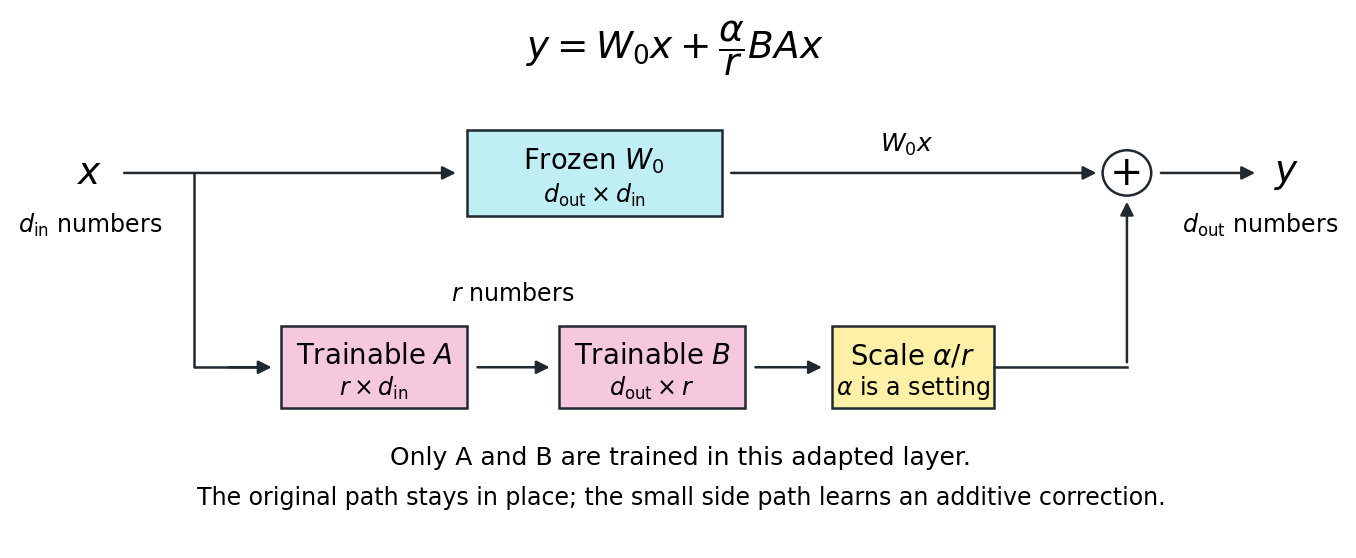


For one linear layer, using **column vectors** and omitting biases:

$$y=W_0x+\underbrace{\frac{\alpha}{r}BA}_{\Delta W}x.$$

Here $d_{\mathrm{in}}$ and $d_{\mathrm{out}}$ are the dimensions of input and output vectors. The symbol $\times$ in a shape means “rows by columns.”

| Symbol | Meaning | Shape or value |
| :--- | :--- | :--- |
| $x$ | Input feature vector | $d_{\mathrm{in}}\times1$ |
| $y$ | Output feature vector | $d_{\mathrm{out}}\times1$ |
| $W_0$ | Frozen pretrained weights | $d_{\mathrm{out}}\times d_{\mathrm{in}}$ |
| $A$ | Trainable projection to a narrow intermediate vector | $r\times d_{\mathrm{in}}$ |
| $B$ | Trainable projection back to the output width | $d_{\mathrm{out}}\times r$ |
| $r$ | Chosen intermediate width; a bound on the update's rank | Small positive integer |
| $\alpha$ | Fixed hyperparameter controlling the correction's scale | Scalar; scale is $\alpha/r$ |
| $\Delta W$ | Learned, scaled correction to the weights | $d_{\mathrm{out}}\times d_{\mathrm{in}}$ |

**Why "low rank"?** Matrix rank is the number of independent rows (or columns). All corrections pass through just $r$ intermediate features, so $\operatorname{rank}(BA)\leq r$. LoRA learns a small-rank **change**; it does not require $W_0$ itself to have low rank. A larger $r$ gives more capacity but trains more parameters.

With PEFT's default LoRA initialization, $A$ is random and $B$ is zero. The correction therefore starts at zero.


Inside ViT, $x$ is **one token's hidden feature vector**, rather than the raw image pixels.


## 2. A tiny numerical example

Take $d_{\mathrm{in}}=5$, $d_{\mathrm{out}}=4$, $r=1$, and $\alpha=1$. These **original, illustrative nonzero values** represent an adapter after some learning, rather than its initialization. Each row of $BA$ is a scaled copy of the row in $A$.

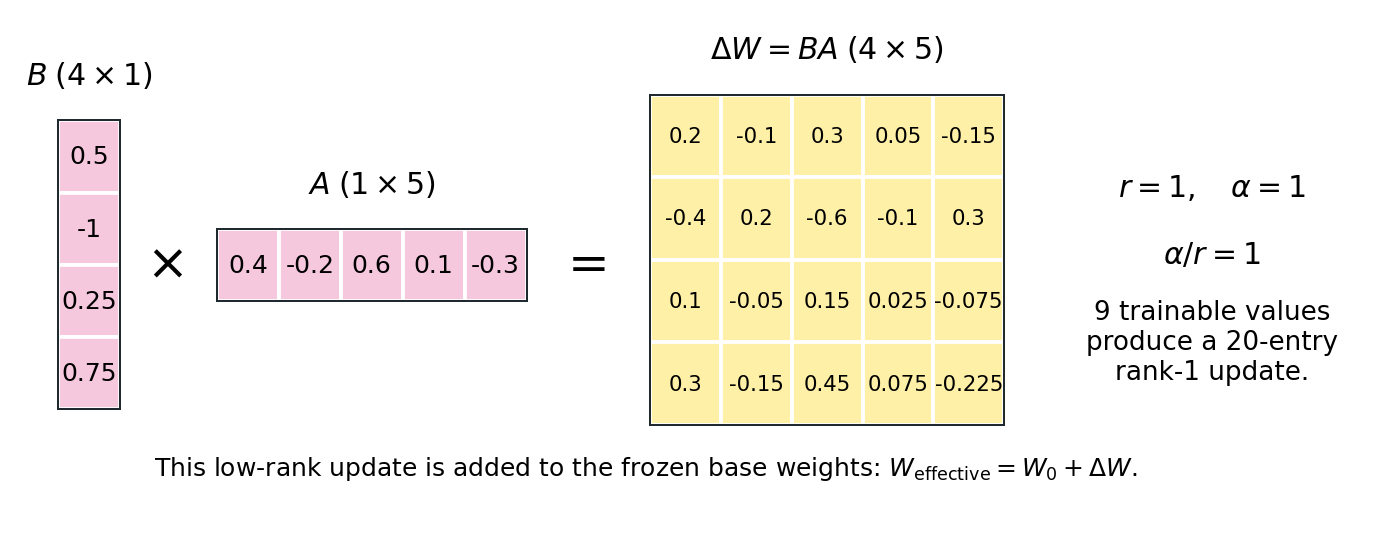


In [2]:
import numpy as np
np.set_printoptions(precision=4, suppress=True)

W0 = np.array([[ .2, -.4,  .1,  .3, -.2],
               [ .5,  .1, -.3,  .2,  .4],
               [-.1,  .6,  .2, -.5,  .1],
               [ .3, -.2,  .4,  .1, -.6]])
A = np.array([[.4, -.2, .6, .1, -.3]])
B = np.array([[.5], [-1.], [.25], [.75]])
x = np.array([[1.], [-1.], [2.], [0.], [.5]])
r, alpha = 1, 1

delta_W = (alpha / r) * (B @ A)   # @ means matrix multiplication
base_output = W0 @ x
correction = (alpha / r) * B @ (A @ x)
y = base_output + correction

print("Base output: ", base_output.ravel())
print("Correction:  ", correction.ravel())
print("LoRA output: ", y.ravel())
print("Rank of the correction:", np.linalg.matrix_rank(delta_W))
# Merging the learned correction into W0 gives the same result at inference.
assert np.allclose(y, (W0 + delta_W) @ x)


Base output:  [ 0.7   0.   -0.25  1.  ]
Correction:   [ 0.825  -1.65    0.4125  1.2375]
LoRA output:  [ 1.525  -1.65    0.1625  2.2375]
Rank of the correction: 1


## 3. Count the trainable parameters

Full fine-tuning of one matrix trains $d_{\mathrm{out}}d_{\mathrm{in}}$ entries. LoRA trains $r(d_{\mathrm{in}}+d_{\mathrm{out}})$ instead.

Our small ViT uses **width 192**. At **rank 4**, one query or value projection needs **1,536** LoRA parameters, compared with **36,864** full weights. The scale $\alpha/r$ adds no trainable parameters. The frozen weights remain stored; savings concern trainable parameters, gradients, and optimizer state, rather than the same percentage of total model memory.


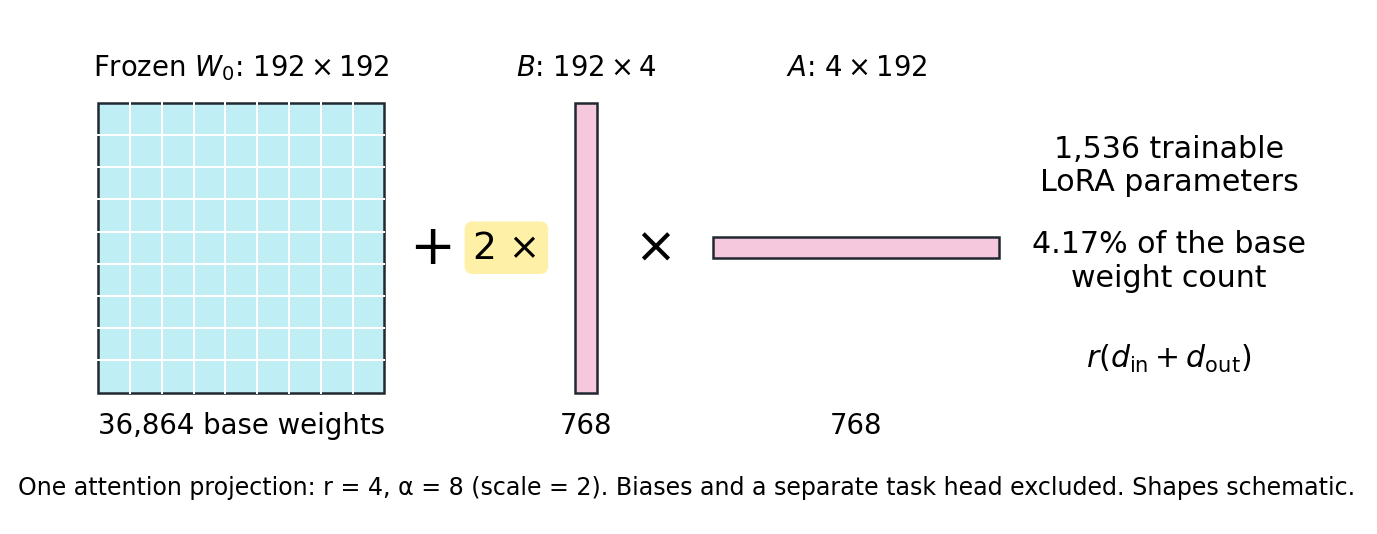


## 4. Where LoRA goes in a Vision Transformer

ViT turns image patches into tokens and mixes their information through self-attention. In our model, a $224\times224$ image gives $N=14\times14=196$ patches of $16\times16$ pixels; $N$ is the number of patches. A **classification (CLS) token** is added; its final vector feeds the classifier.

We adapt the attention **query (Q) and value (V) projections** in all 12 blocks. Their original weights, the key projections, and the rest of the pretrained backbone stay frozen. A **new three-class classifier** also trains and is saved with the adapters.


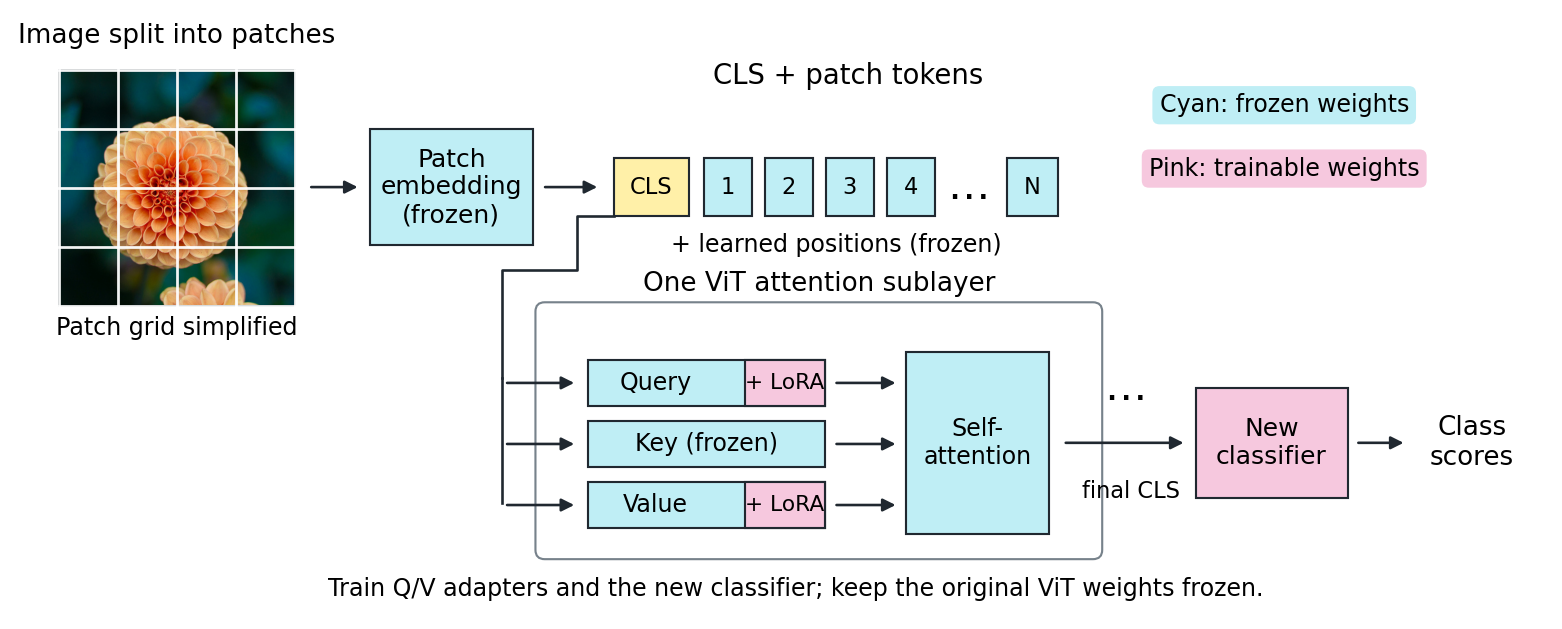

The flower illustrates patching; the experiment below uses leaf photographs. The diagram omits residual connections, MLPs, normalization, and the remaining blocks. In this experiment, **$r=4$ and $\alpha=8$**, giving scale $2$. The earlier hand-calculation used $r=1$ only to make the numbers easy to inspect.


In [3]:
import os
# Keep downloads and dataset preparation free of interactive widgets.
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
os.environ["HF_DATASETS_DISABLE_PROGRESS_BARS"] = "1"

import torch
from torch.utils.data import DataLoader
from transformers import AutoImageProcessor, AutoModelForImageClassification, set_seed
from datasets import load_dataset, disable_progress_bars as disable_dataset_bars
from huggingface_hub.utils import disable_progress_bars as disable_hub_bars
from peft import LoraConfig, get_peft_model

disable_dataset_bars()
disable_hub_bars()

set_seed(42)
torch.set_num_threads(2)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
data = load_dataset("AI-Lab-Makerere/beans", token=False)
class_names = data["train"].features["labels"].names
model_id = "WinKawaks/vit-tiny-patch16-224"
processor = AutoImageProcessor.from_pretrained(model_id, use_fast=False, token=False)
base_model = AutoModelForImageClassification.from_pretrained(
    model_id, num_labels=len(class_names),
    id2label=dict(enumerate(class_names)),
    label2id={name: i for i, name in enumerate(class_names)},
    ignore_mismatched_sizes=True, use_safetensors=True, token=False,
).to(device)
config = LoraConfig(
    r=4, lora_alpha=8, target_modules=["query", "value"],
    modules_to_save=["classifier"], bias="none",
)
# Generic PEFT wrapper: the input is pixel_values, not text tokens.
model = get_peft_model(base_model, config)
print("Device:", device, "| Classes:", class_names)
model.print_trainable_parameters()


Fast image processor class <class 'transformers.models.vit.image_processing_vit_fast.ViTImageProcessorFast'> is available for this model. Using slow image processor class. To use the fast image processor class set `use_fast=True`.
Some weights of ViTForImageClassification were not initialized from the model checkpoint at WinKawaks/vit-tiny-patch16-224 and are newly initialized because the shapes did not match:
- classifier.bias: found shape torch.Size([1000]) in the checkpoint and torch.Size([3]) in the model instantiated
- classifier.weight: found shape torch.Size([1000, 192]) in the checkpoint and torch.Size([3, 192]) in the model instantiated
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Device: cpu | Classes: ['angular_leaf_spot', 'bean_rust', 'healthy']
trainable params: 37,443 || all params: 5,562,438 || trainable%: 0.6731


In [4]:
train_data = data["train"].shuffle(seed=42).select(range(600))
eval_data = data["validation"].shuffle(seed=42).select(range(100))

def collate(examples):
    batch = processor(
        images=[row["image"].convert("RGB") for row in examples],
        return_tensors="pt",
    )
    batch["labels"] = torch.tensor([row["labels"] for row in examples],
                                  dtype=torch.long)
    return batch

train_loader = DataLoader(train_data, batch_size=16, shuffle=True, collate_fn=collate)
eval_loader = DataLoader(eval_data, batch_size=16, collate_fn=collate)
print("600 training images; 100 held-out validation images")


600 training images; 100 held-out validation images


## 5. Train with the usual image-classification loss

The **image processor** resizes photographs to $224\times224$ and normalizes their color channels. Do not normalize them a second time. The `pixel_values` tensor has shape **batch size × 3 color channels × 224 × 224**.

The model produces three **logits** (class scores). Supplying `labels` computes standard **cross-entropy loss**; LoRA needs no special loss. Backpropagation updates only the LoRA matrices and new classifier. A warning about the replaced classifier is expected.

The “before” score uses a randomly initialized classifier. Validation images never enter the optimizer. This small run teaches the mechanism; results and timing depend on the runtime.


In [5]:
from time import perf_counter

@torch.no_grad()
def accuracy():
    model.eval()
    correct, total = 0, 0
    for batch in eval_loader:
        batch = {key: value.to(device) for key, value in batch.items()}
        predictions = model(**batch).logits.argmax(dim=-1)
        correct += (predictions == batch["labels"]).sum().item()
        total += batch["labels"].numel()
    return correct / total

optimizer = torch.optim.AdamW(
    [p for p in model.parameters() if p.requires_grad], lr=1e-3,
)
print(f"Before training: validation accuracy = {accuracy():.1%}")
start = perf_counter()
for epoch in range(2):
    model.train()
    total_loss, seen = 0.0, 0
    for batch in train_loader:
        batch = {key: value.to(device) for key, value in batch.items()}
        optimizer.zero_grad()
        loss = model(**batch).loss
        loss.backward()
        optimizer.step()
        count = batch["labels"].size(0)
        total_loss += loss.item() * count
        seen += count
    print(f"Epoch {epoch + 1}: loss = {total_loss / seen:.3f}, "
          f"validation accuracy = {accuracy():.1%}")
print(f"Training and epoch evaluations: {perf_counter() - start:.1f} seconds")


Before training: validation accuracy = 34.0%
Epoch 1: loss = 0.681, validation accuracy = 88.0%
Epoch 2: loss = 0.215, validation accuracy = 97.0%
Training and epoch evaluations: 175.9 seconds


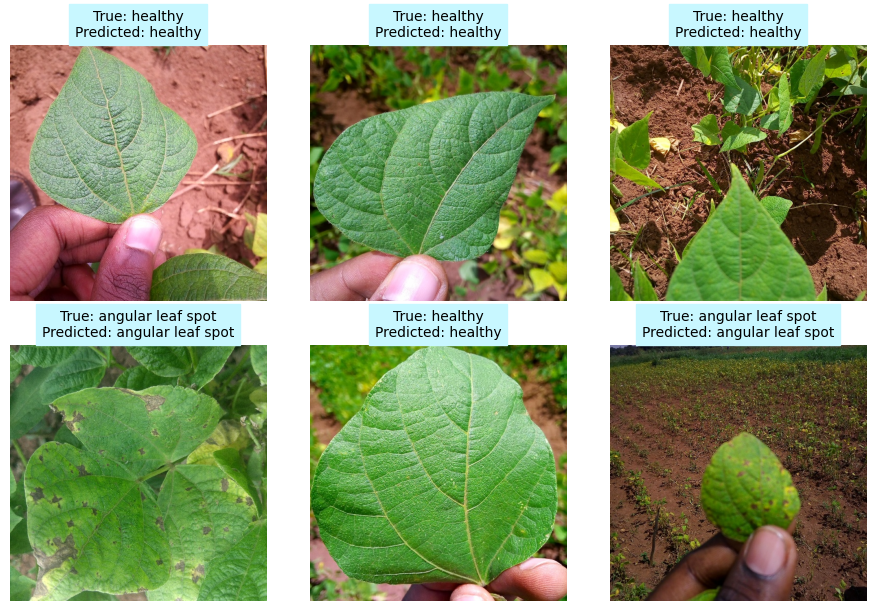

In [6]:
import matplotlib.pyplot as plt

# Show real validation photos with the model's predictions.
examples = [eval_data[i] for i in range(6)]
batch = {key: value.to(device) for key, value in collate(examples).items()}
model.eval()
with torch.no_grad():
    predictions = model(**batch).logits.argmax(dim=-1).cpu().tolist()
fig, axes = plt.subplots(2, 3, figsize=(9, 6), constrained_layout=True)
for ax, row, prediction in zip(axes.flat, examples, predictions):
    ax.imshow(row["image"])
    truth = class_names[row["labels"]].replace("_", " ")
    guess = class_names[prediction].replace("_", " ")
    ax.set_title(f"True: {truth}\nPredicted: {guess}", fontsize=10, color="black",
                 backgroundcolor="#C8F7FF" if prediction == row["labels"] else "#FFD1E8")
    ax.axis("off")
plt.show()


## 6. Save the small adaptation

This saves the **LoRA adapters, trained classifier, and image processor**. Reloading also needs the same base checkpoint configured with the same three classes and label mapping; this is not a standalone copy of the entire ViT.

For inference, the adapters can also be merged: $W_{\mathrm{merged}}=W_0+\Delta W$. Our numerical example verified that the merged weights produce the same result as the two parallel paths.


In [7]:
adapter_folder = "vit_beans_lora"
model.save_pretrained(adapter_folder)
processor.save_pretrained(adapter_folder)
print(f"Saved adapters, classifier, and image processor to {adapter_folder}/")


Saved adapters, classifier, and image processor to vit_beans_lora/


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


**Check your understanding:** What changes if we double $r$? Which ViT parameters train here? Does a trainable-parameter saving of 95% imply a 95% reduction in total model memory?

**References**

- [Hu et al., *LoRA: Low-Rank Adaptation of Large Language Models*](https://arxiv.org/abs/2106.09685) — the same weight-update method also applies to vision models.
- [Hugging Face: image classification using LoRA](https://huggingface.co/docs/peft/main/task_guides/image_classification_lora) and [LoRA configuration](https://huggingface.co/docs/peft/v0.18.0/en/package_reference/lora).
- [Tiny ViT checkpoint](https://huggingface.co/WinKawaks/vit-tiny-patch16-224); [Makerere AI Lab Beans dataset](https://huggingface.co/datasets/AI-Lab-Makerere/beans).
- [Dosovitskiy et al., *An Image Is Worth 16×16 Words*](https://arxiv.org/abs/2010.11929).

Flower photograph: scikit-learn sample image, [Flickr/vultilion](https://www.flickr.com/photos/vultilion/6056698931/)

